# NB-01 — Figuras do pré-processamento (Cap. 2, §2.1)

Gera `preproc_00..07_*.png` (300 dpi) e `manifest.json` em `saidas/NB-01/`. Cada etapa vem de um `PreprocessingPipeline` com flags ligados cumulativamente — parâmetros e ordem são os da plataforma.

**Figuras ilustrativas:** `02_normalizacao` usa entrada degradada (achado A, opção 1 — *opção 1 confirmada pelo autor em 10-11-2026*), pois a página real já ocupa 1–255. O deskew (achado B) segue como está no código; ver diagnóstico abaixo.

In [1]:
# Parâmetros
from pathlib import Path
ENTRADA = Path.home() / 'text_tcc_unb/unbtex-example/figuras/1680-069.png'
SAIDA = Path('saidas/NB-01')
SEED = 0  # sem aleatoriedade neste notebook; mantido por convenção
ILUSTRAR_NORMALIZACAO = True  # achado A.1: entrada degradada (90–200), matrizes antes/depois

In [2]:
import sys
sys.path.insert(0, 'lib')
import json
import matplotlib.pyplot as plt
import preproc_figs as P

RAIZ = Path.cwd().parent  # raiz do htr_workbench (para o commit no manifest)
caminhos, manifest, imagens = P.gerar(ENTRADA, SAIDA, ILUSTRAR_NORMALIZACAO, raiz_projeto=RAIZ)
print(len(caminhos), 'figuras em', SAIDA.resolve())

8 figuras em ~/htr_workbench/notebooks/saidas/NB-01


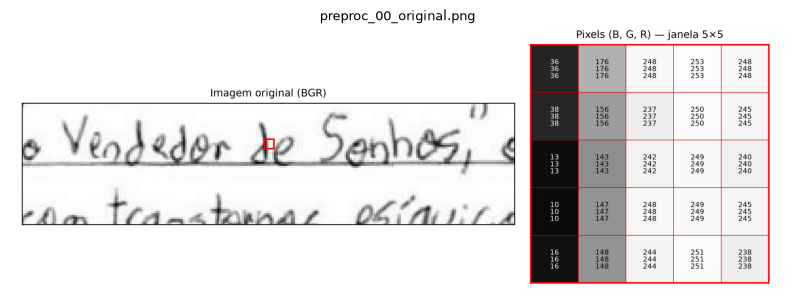

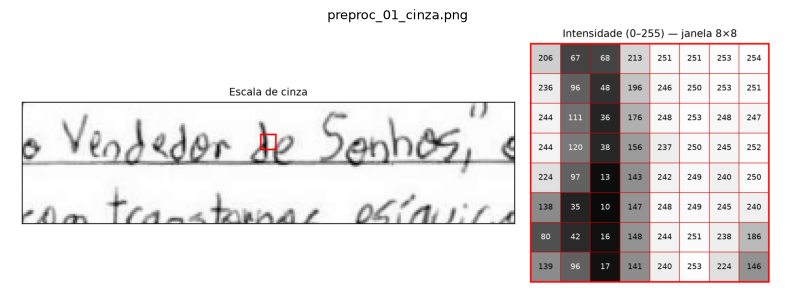

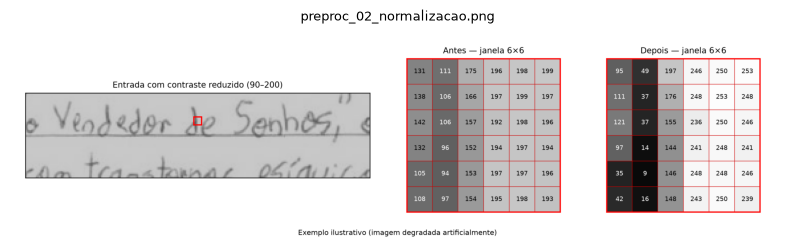

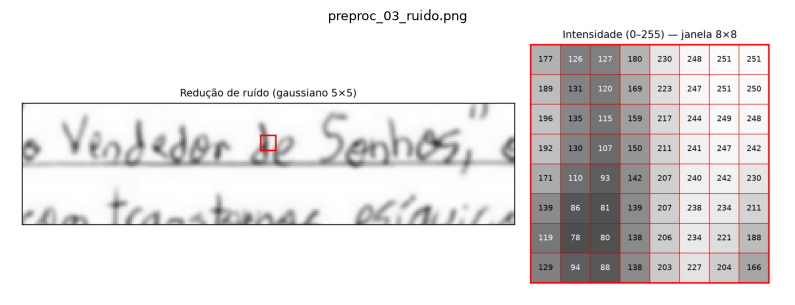

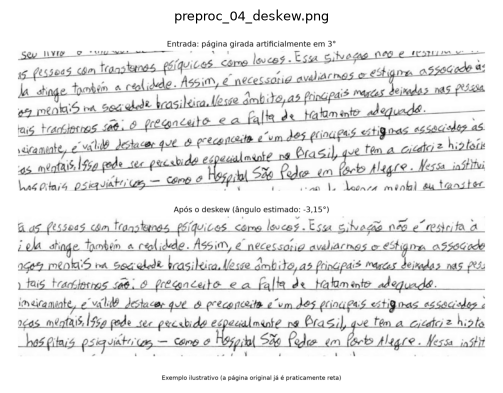

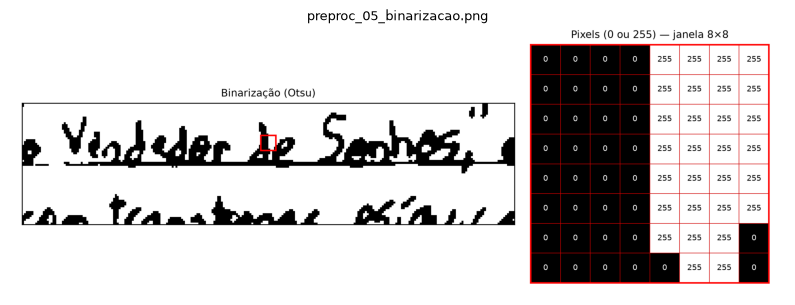

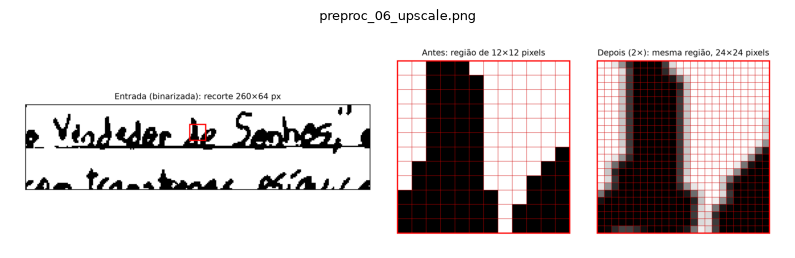

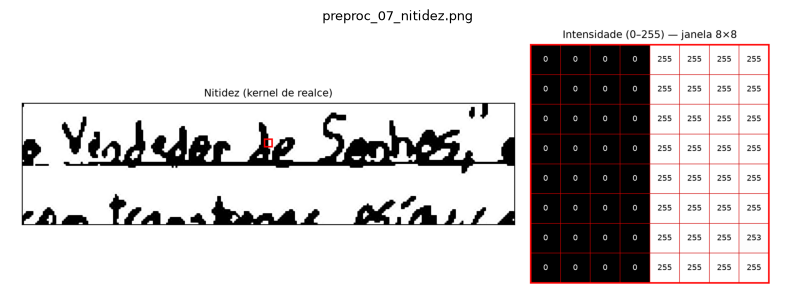

In [3]:
for c in caminhos:
    plt.figure(figsize=(10, 4.6))
    plt.imshow(plt.imread(c)); plt.axis('off'); plt.title(c.name, fontsize=9)
    plt.show()

## Diagnóstico dos achados A e B

In [4]:
print('A — dif. máx. após normalizar a página real:', manifest['normalizacao_real_max_dif'])
print('A — ilustração:', manifest['normalizacao_ilustrativa'])
print('B — deskew:', json.dumps(manifest['deskew_diagnostico'], indent=2))

A — dif. máx. após normalizar a página real: 1
A — ilustração: {'antes_min_max': [90, 200], 'depois_min_max': [0, 255]}
B — deskew: {
  "angulo_estimado_pagina": -0.15,
  "pixels_alterados_pagina": 0,
  "pixels_alterados_copia_girada_3graus": 1099345,
  "total_pixels": 1212640
}


## Aceite
- 8 PNGs gerados.
- Parâmetros por etapa em `manifest['pipeline_por_etapa']`.

In [5]:
assert len(list(SAIDA.glob('preproc_0*.png'))) == 8
print(json.dumps(manifest['pipeline_por_etapa']['07_nitidez'], indent=2))

{
  "grayscale": true,
  "normalize": true,
  "normalize_alpha": 0,
  "normalize_beta": 255,
  "noise_reduction": true,
  "noise_method": "gaussian",
  "noise_ksize": 5,
  "noise_sigma": 0,
  "deskew": true,
  "binarize": true,
  "binarize_method": "otsu",
  "binarize_threshold": 127,
  "binarize_block_size": 11,
  "binarize_C": 2,
  "upscale": true,
  "upscale_factor": 2.0,
  "sharpen": true
}
